# Energy Journal

Line chart for the supplied 2023-2050 data series.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "nbs":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import pandas as pd

import src.matplotlib_style  # noqa: F401


In [2]:
years = list(range(2023, 2051))
values = [
    0.00,
    0.00,
    0.00,
    0.00,
    0.00,
    -0.96,
    -1.76,
    -2.55,
    -4.61,
    -6.30,
    -8.26,
    -10.25,
    -12.67,
    -14.82,
    -16.97,
    -18.30,
    -19.82,
    -21.32,
    -23.36,
    -24.64,
    -25.93,
    -27.41,
    -29.28,
    -30.41,
    -31.60,
    -32.84,
    -34.26,
    -35.82,
]

energy_journal = pd.DataFrame({"Year": years, "Value": values})
energy_journal


,Year,Value
0,2023,0.00
1,2024,0.00
2,2025,0.00
3,2026,0.00
4,2027,0.00
5,2028,-0.96
6,2029,-1.76
7,2030,-2.55
8,2031,-4.61
9,2032,-6.30


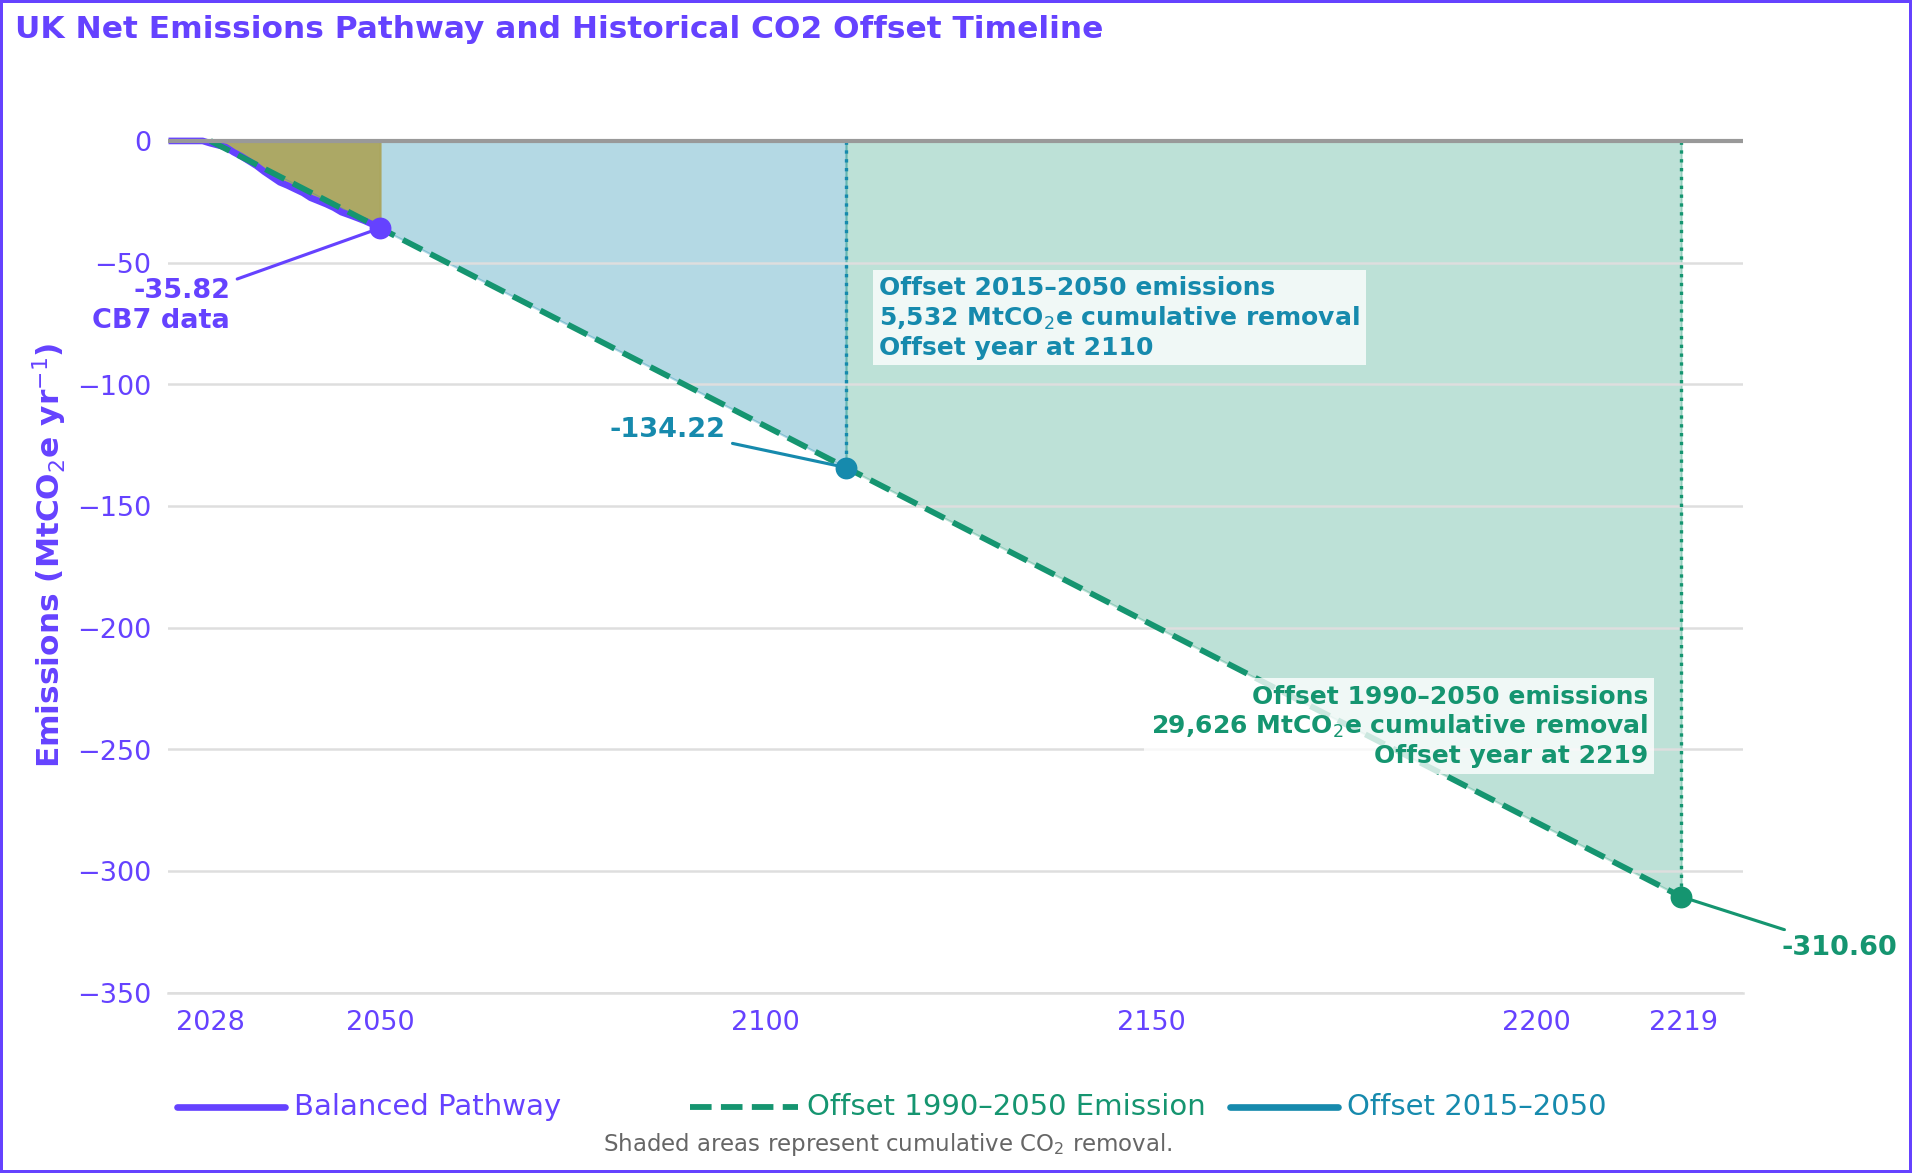

In [3]:
from matplotlib.lines import Line2D

purple = "#6542ff"
gold = "#f2b134"
green = "#159570"
blue = "#168aad"
coral = "#e2574c"
grid = "#dedede"

offset_emissions = 29_626  # MtCO2e emitted between 1990 and 2050
pathway_start_year = 2028
pathway_end_year = 2050
pathway_end_value = abs(energy_journal.loc[energy_journal["Year"] == 2050, "Value"].iloc[0])
pathway_slope = pathway_end_value / (pathway_end_year - pathway_start_year)
offset_duration = (2 * offset_emissions / pathway_slope) ** 0.5
offset_year = pathway_start_year + offset_duration
offset_end_value = -pathway_slope * offset_duration
offset_2015_emissions = 5_532  # MtCO2e emitted between 2015 and 2050
offset_2015_duration = (2 * offset_2015_emissions / pathway_slope) ** 0.5
offset_2015_year = pathway_start_year + offset_2015_duration
offset_2015_end_value = -pathway_slope * offset_2015_duration

fig, ax = plt.subplots(figsize=(12, 8))
fig.set_layout_engine(None)
fig.patch.set_facecolor("white")
fig.patch.set_edgecolor(purple)
fig.patch.set_linewidth(2)

ax.fill_between(
    energy_journal["Year"],
    energy_journal["Value"],
    0,
    where=energy_journal["Value"] <= 0,
    color=gold,
    alpha=0.92,
)
ax.plot(
    energy_journal["Year"],
    energy_journal["Value"],
    color=purple,
    linewidth=3.2,
)
# Shaded areas show cumulative removals (the integral below zero).
ax.fill_between(
    [pathway_start_year, offset_2015_year],
    [0, offset_2015_end_value],
    0,
    color=blue,
    alpha=0.32,
    zorder=1,
)
ax.fill_between(
    [offset_2015_year, offset_year],
    [offset_2015_end_value, offset_end_value],
    0,
    color=green,
    alpha=0.28,
    zorder=1,
)
ax.plot(
    [pathway_start_year, offset_year],
    [0, offset_end_value],
    color=green,
    linewidth=2.8,
    linestyle="--",
    label="Offset 1990–2050 Emission",
)
ax.vlines(
    offset_2015_year, 0, offset_2015_end_value, color=blue, linewidth=1.6, linestyle=":"
)
ax.vlines(offset_year, 0, offset_end_value, color=green, linewidth=1.6, linestyle=":")
ax.scatter(offset_2015_year, offset_2015_end_value, color=blue, s=90, zorder=6)
ax.annotate(
    f"{offset_2015_end_value:.2f}",
    xy=(offset_2015_year, offset_2015_end_value),
    xytext=(-58, 12),
    textcoords="offset points",
    color=blue,
    fontsize=13,
    weight="bold",
    ha="right",
    va="bottom",
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.85},
    arrowprops={"arrowstyle": "-", "color": blue, "linewidth": 1.5},
)
ax.annotate(
    f"Offset 2015–2050 emissions\n5,532 MtCO$_2$e cumulative removal\nOffset year at {offset_2015_year:.0f}",
    xy=(offset_2015_year, offset_2015_end_value),
    xytext=(16, 52),
    textcoords="offset points",
    color=blue,
    fontsize=12,
    weight="bold",
    ha="left",
    va="bottom",
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 3, "alpha": 0.78},
)
ax.scatter(offset_year, offset_end_value, color=green, s=90, zorder=5)
ax.annotate(
    f"{offset_end_value:.2f}",
    xy=(offset_year, offset_end_value),
    xytext=(48, -18),
    textcoords="offset points",
    color=green,
    fontsize=13,
    weight="bold",
    ha="left",
    va="top",
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.85},
    arrowprops={"arrowstyle": "-", "color": green, "linewidth": 1.5},
)
ax.annotate(
    f"Offset 1990–2050 emissions\n29,626 MtCO$_2$e cumulative removal\nOffset year at {offset_year:.0f}",
    xy=(offset_year, offset_end_value),
    xytext=(-16, 62),
    textcoords="offset points",
    color=green,
    fontsize=12,
    weight="bold",
    ha="right",
    va="bottom",
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 3, "alpha": 0.78},
)
ax.scatter(2050, -35.82, color=purple, s=90, zorder=5)
ax.annotate(
    "-35.82\nCB7 data",
    xy=(2050, -35.82),
    xytext=(-72, -24),
    textcoords="offset points",
    color=purple,
    fontsize=13,
    weight="bold",
    ha="right",
    va="top",
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.85},
    arrowprops={"arrowstyle": "-", "color": purple, "linewidth": 1.5},
)
ax.axhline(0, color="#999999", linewidth=2)

ax.set_xlim(2022.5, offset_year + 8)
ax.set_ylim(offset_end_value - 25, 10)
ax.set_xticks([2028, 2050, 2100, 2150, 2200, round(offset_year)])
ax.set_yticks(list(range(0, -351, -50)))
ax.set_ylabel("Emissions (MtCO$_2$e yr$^{-1}$)", color=purple, fontsize=15, weight="bold")
ax.tick_params(axis="both", colors=purple, labelsize=13, length=0, pad=8)
ax.grid(axis="y", color=grid, linewidth=1.2)
ax.grid(axis="x", visible=False)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(grid)
ax.spines["bottom"].set_linewidth(1.2)

fig.text(
    0.015,
    0.965,
    "UK Net Emissions Pathway and Historical CO2 Offset Timeline",
    color=purple,
    fontsize=15,
    weight="bold",
    va="top",
)
fig.add_artist(
    Line2D(
        [0.105, 0.165],
        [0.055, 0.055],
        transform=fig.transFigure,
        color=purple,
        linewidth=3.2,
        solid_capstyle="round",
    )
)
fig.text(0.17, 0.055, "Balanced Pathway", color=purple, fontsize=14, va="center")
fig.add_artist(
    Line2D(
        [0.39, 0.45],
        [0.055, 0.055],
        transform=fig.transFigure,
        color=green,
        linewidth=2.8,
        linestyle="--",
        solid_capstyle="round",
    )
)
fig.text(0.455, 0.055, "Offset 1990–2050 Emission", color=green, fontsize=14, va="center")
fig.add_artist(
    Line2D(
        [0.69, 0.75],
        [0.055, 0.055],
        transform=fig.transFigure,
        color=blue,
        linewidth=3.2,
        solid_capstyle="round",
    )
)
fig.text(0.755, 0.055, "Offset 2015–2050", color=blue, fontsize=14, va="center")
fig.text(
    0.5,
    0.018,
    "Shaded areas represent cumulative CO$_2$ removal.",
    color="#666666",
    fontsize=11,
    ha="center",
)
ax.set_position([0.1, 0.15, 0.875, 0.73])

plt.show()


# Illustrative post-2050 engineered CO$_2$ removal pathways

The modelled engineered CO$_2$ removal trajectory (negative values denote net
removals) runs 2023–2050. Beyond 2050, where no further data are supplied, two
illustrative extrapolations are compared: the removal rate held constant at its
2050 value, and the removal rate continuing to grow linearly at the pathway's
2028–2050 average gradient (−1.63 MtCO$_2$e yr$^{-2}$). Shaded regions show the
cumulative removal (time integral) implied by each case, reported in GtCO$_2$e.
These post-2050 pathways are illustrative extrapolations of engineered removal
capacity only — they are not CCC forecasts, and they do not represent total UK
net or residual emissions.

In [4]:
extension_start_year = 2050
extension_end_year = 2100
extension_start_value = float(energy_journal.loc[energy_journal["Year"] == 2050, "Value"].iloc[0])
# Continue the modelled trajectory's average gradient (-1.63 MtCO2e/yr^2) past 2050
# instead of holding it flat, as one of two illustrative post-2050 extrapolations.
extension_gradient = -pathway_slope
extension_end_value = extension_start_value + extension_gradient * (
    extension_end_year - extension_start_year
)


def trapezoidal_area(xs, ys):
    return sum((ys[i] + ys[i - 1]) / 2 * (xs[i] - xs[i - 1]) for i in range(1, len(xs)))


# Cumulative removal from the modelled 2023-2050 trajectory (trapezoidal integration).
cumulative_2023_2050 = trapezoidal_area(
    energy_journal["Year"].tolist(), energy_journal["Value"].tolist()
)
# Linear-growth case: additional removal from extending the gradient to 2100 (a trapezoid).
extension_area = (
    (extension_start_value + extension_end_value) / 2 * (extension_end_year - extension_start_year)
)
cumulative_2023_2100 = cumulative_2023_2050 + extension_area

# Constant-rate case: removal rate held at the 2050 value from 2050 to 2100.
flat_reference_area = extension_start_value * (extension_end_year - extension_start_year)
extra_removal_from_gradient = extension_area - flat_reference_area

cumulative_2023_2050_gt = cumulative_2023_2050 / 1000
extension_area_gt = extension_area / 1000
cumulative_2023_2100_gt = cumulative_2023_2100 / 1000
flat_reference_area_gt = flat_reference_area / 1000
extra_removal_from_gradient_gt = extra_removal_from_gradient / 1000

print(f"Cumulative removal 2023-2050: {abs(cumulative_2023_2050_gt):,.2f} GtCO2e")
print(
    f"Additional removal 2050-2100 (gradient {extension_gradient:.2f} MtCO2e/yr^2): "
    f"{abs(extension_area_gt):,.2f} GtCO2e"
)
print(f"Linear-growth case, cumulative removal by 2100: {abs(cumulative_2023_2100_gt):,.2f} GtCO2e")
print(f"Emissions at 2100 (linear-growth case): {extension_end_value:.0f} MtCO2e/yr")
print(f"Constant-rate case, removal 2050-2100: {abs(flat_reference_area_gt):,.2f} GtCO2e")
print(
    f"Extra removal from linear growth vs. constant rate: "
    f"{abs(extra_removal_from_gradient_gt):,.2f} GtCO2e"
)


Cumulative removal 2023-2050: 0.42 GtCO2e
Additional removal 2050-2100 (gradient -1.63 MtCO2e/yr^2): 3.83 GtCO2e
Linear-growth case, cumulative removal by 2100: 4.24 GtCO2e
Emissions at 2100 (linear-growth case): -117 MtCO2e/yr
Constant-rate case, removal 2050-2100: 1.79 GtCO2e
Extra removal from linear growth vs. constant rate: 2.04 GtCO2e


C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_29868\3697006895.py:166: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


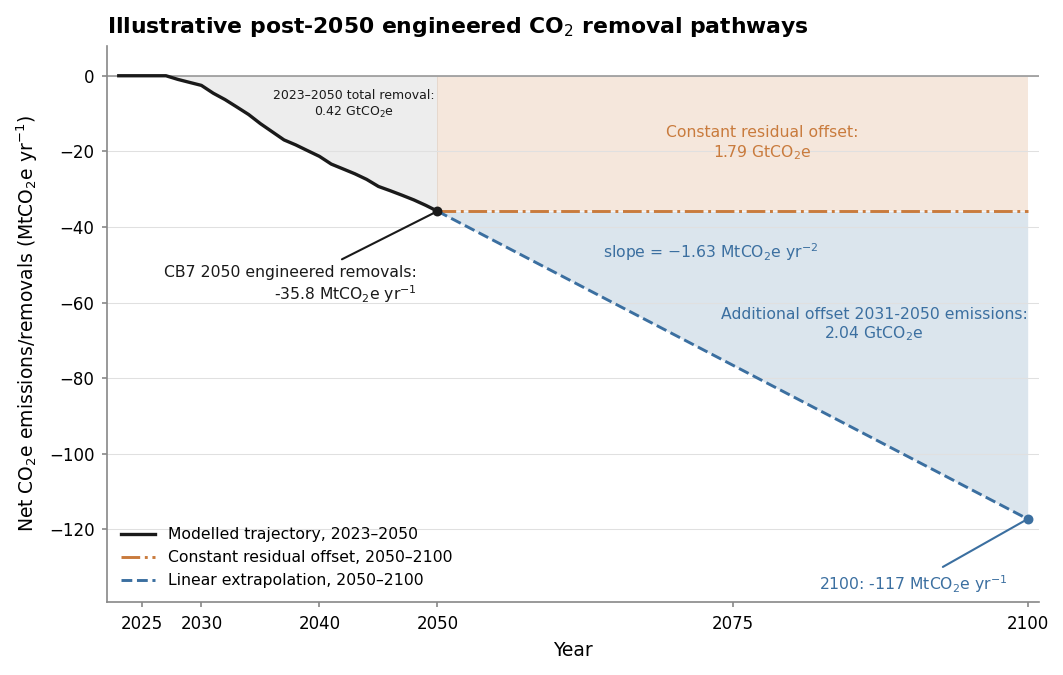

In [5]:
ink = "#1a1a1a"
extrap_blue = "#3b6fa0"
const_orange = "#c97b3d"

fig, ax = plt.subplots(figsize=(7.2, 4.6))
fig.patch.set_facecolor("white")

# Modelled trajectory, 2023-2050.
ax.plot(
    energy_journal["Year"],
    energy_journal["Value"],
    color=ink,
    linewidth=1.6,
    label="Modelled trajectory, 2023–2050",
    zorder=3,
)
ax.fill_between(
    energy_journal["Year"],
    energy_journal["Value"],
    0,
    color=ink,
    alpha=0.08,
    linewidth=0,
    zorder=1,
)

# Constant residual offset, 2050-2100 (illustrative extrapolation).
flat_reference_years = [extension_start_year, extension_end_year]
flat_reference_values = [extension_start_value, extension_start_value]
ax.plot(
    flat_reference_years,
    flat_reference_values,
    color=const_orange,
    linewidth=1.4,
    linestyle="-.",
    label="Constant residual offset, 2050–2100",
    zorder=3,
)
ax.fill_between(
    flat_reference_years,
    flat_reference_values,
    0,
    color=const_orange,
    alpha=0.18,
    linewidth=0,
    zorder=1,
)

# Linear extrapolation at the modelled gradient, 2050-2100 (illustrative extrapolation).
extension_years = [extension_start_year, extension_end_year]
extension_values = [extension_start_value, extension_end_value]
ax.plot(
    extension_years,
    extension_values,
    color=extrap_blue,
    linewidth=1.4,
    linestyle="--",
    label="Linear extrapolation, 2050–2100",
    zorder=3,
)
# Shade only the incremental area between the constant-rate and linear-extrapolation lines.
ax.fill_between(
    extension_years,
    extension_values,
    flat_reference_values,
    color=extrap_blue,
    alpha=0.18,
    linewidth=0,
    zorder=1,
)

ax.axhline(0, color="#999999", linewidth=0.8, zorder=2)

ax.scatter([extension_start_year], [extension_start_value], color=ink, s=14, zorder=4)
ax.scatter([extension_end_year], [extension_end_value], color=extrap_blue, s=14, zorder=4)


def slope_value_at(year):
    return extension_start_value + extension_gradient * (year - extension_start_year)


ax.annotate(
    f"CB7 2050 engineered removals:\n{extension_start_value:.1f} MtCO$_2$e yr$^{{-1}}$",
    xy=(extension_start_year, extension_start_value),
    xytext=(-10, -26),
    textcoords="offset points",
    fontsize=7.5,
    color=ink,
    ha="right",
    va="top",
    arrowprops={"arrowstyle": "-", "color": ink, "linewidth": 1.0},
)
# Positioned and sized so the two-line label sits fully inside the narrow 2023-2050 wedge.
ax.annotate(
    f"2023–2050 total removal:\n{abs(cumulative_2023_2050_gt):.2f} GtCO$_2$e",
    xy=(2042.9, -7.58),
    fontsize=6,
    color=ink,
    ha="center",
    va="center",
)
ax.annotate(
    f"Constant residual offset:\n{abs(flat_reference_area_gt):.2f} GtCO$_2$e",
    xy=(extension_start_year + 0.55 * (extension_end_year - extension_start_year), extension_start_value / 2),
    fontsize=7.5,
    color=const_orange,
    ha="center",
    va="center",
)
slope_label_x = extension_start_year + 0.28 * (extension_end_year - extension_start_year)
slope_label_y = slope_value_at(slope_label_x) + 9
ax.annotate(
    "slope = −1.63 MtCO$_2$e yr$^{-2}$",
    xy=(slope_label_x, slope_label_y),
    fontsize=7.5,
    color=extrap_blue,
    ha="left",
    va="bottom",
)
# Shifted left (from 0.85 to 0.74 of the 2050-2100 span) so the label stays inside the widening triangle instead of spilling past x=2100.
growth_label_x = extension_start_year + 0.74 * (extension_end_year - extension_start_year)
growth_label_y = (extension_start_value + slope_value_at(growth_label_x)) / 2
ax.annotate(
    f"Additional offset 2031-2050 emissions:\n{abs(extra_removal_from_gradient_gt):.2f} GtCO$_2$e",
    xy=(growth_label_x, growth_label_y),
    fontsize=7.5,
    color=extrap_blue,
    ha="center",
    va="center",
)
ax.annotate(
    f"2100: {extension_end_value:.0f} MtCO$_2$e yr$^{{-1}}$",
    xy=(extension_end_year, extension_end_value),
    xytext=(-10, -26),
    textcoords="offset points",
    fontsize=7.5,
    color=extrap_blue,
    ha="right",
    va="top",
    arrowprops={"arrowstyle": "-", "color": extrap_blue, "linewidth": 1.0},
)

ax.set_title(
    "Illustrative post-2050 engineered CO$_2$ removal pathways",
    fontsize=10.5,
    weight="bold",
    loc="left",
)
ax.set_xlabel("Year", fontsize=9)
ax.set_ylabel("Net CO$_2$e emissions/removals (MtCO$_2$e yr$^{-1}$)", fontsize=9)
ax.set_xlim(2022, extension_end_year + 1)
ax.set_ylim(extension_end_value - 22, 8)
ax.set_xticks([2025, 2030, 2040, 2050, 2075, 2100])
ax.tick_params(axis="both", labelsize=8, length=2.5, color="#888888")
ax.grid(axis="y", color="#e0e0e0", linewidth=0.5, zorder=0)
ax.grid(axis="x", visible=False)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#888888")
    ax.spines[spine].set_linewidth(0.8)

ax.legend(loc="lower left", fontsize=7.5, frameon=False, handlelength=2.2)

fig.tight_layout()
plt.show()


# Post-2050 pathway with an added 5.76 GtCO$_2$e extension

Same chart as above, with one further illustrative line added. It starts from
the modelled 2050 point and follows a steeper constant gradient chosen so that
its own 2050–2100 cumulative removal totals 5.76 GtCO$_2$e. For comparison, the
modelled-gradient extrapolation totals 3.83 GtCO$_2$e and the constant-rate case
totals 1.79 GtCO$_2$e over the same period.

Third pathway slope: -3.18 MtCO2e/yr^2
Third pathway 2100 value: -195 MtCO2e/yr
Third pathway cumulative removal 2050-2100: 5.76 GtCO2e
Font resolved to: C:\Windows\Fonts\arial.ttf


C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_29868\1744245961.py:240: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


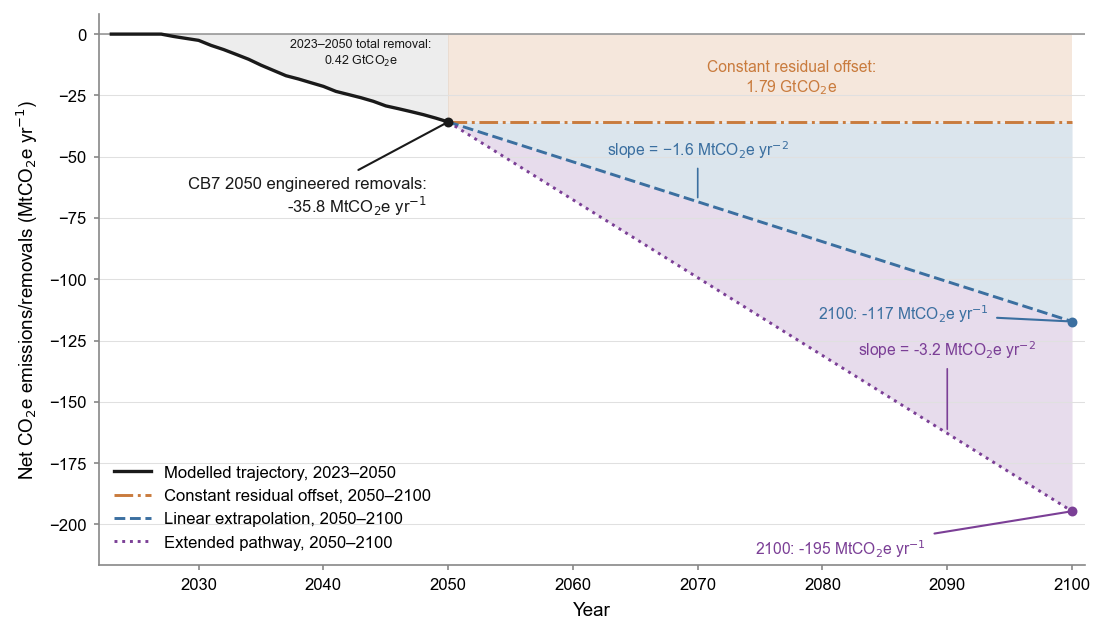

In [6]:
# Third illustrative pathway: a steeper constant-gradient line from the same
# 2050 point, sized so its own 2050-2100 cumulative removal totals 5.76 GtCO2e.
third_target_area_gt = -5.761
third_target_area = third_target_area_gt * 1000
third_end_value = (
    2 * third_target_area / (extension_end_year - extension_start_year) - extension_start_value
)
third_gradient = (third_end_value - extension_start_value) / (
    extension_end_year - extension_start_year
)
third_area_gt = third_target_area_gt

print(f"Third pathway slope: {third_gradient:.2f} MtCO2e/yr^2")
print(f"Third pathway 2100 value: {third_end_value:.0f} MtCO2e/yr")
print(f"Third pathway cumulative removal 2050-2100: {abs(third_area_gt):.2f} GtCO2e")

# Elsevier "Energy" artwork requirements: Arial/Helvetica lettering, embeddable
# (TrueType) fonts in vector output, figure sized to the journal's double-column
# width (190 mm / 7.48 in).
from matplotlib import font_manager

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
print("Font resolved to:", font_manager.findfont("Arial"))

ink = "#1a1a1a"
extrap_blue = "#3b6fa0"
const_orange = "#c97b3d"
extend_purple = "#7b3f96"

fig, ax = plt.subplots(figsize=(7.48, 4.33))
fig.patch.set_facecolor("white")

# Modelled trajectory, 2023-2050.
ax.plot(
    energy_journal["Year"],
    energy_journal["Value"],
    color=ink,
    linewidth=1.6,
    label="Modelled trajectory, 2023–2050",
    zorder=3,
)
ax.fill_between(
    energy_journal["Year"],
    energy_journal["Value"],
    0,
    color=ink,
    alpha=0.08,
    linewidth=0,
    zorder=1,
)

# Constant residual offset, 2050-2100 (illustrative extrapolation).
flat_reference_years = [extension_start_year, extension_end_year]
flat_reference_values = [extension_start_value, extension_start_value]
ax.plot(
    flat_reference_years,
    flat_reference_values,
    color=const_orange,
    linewidth=1.4,
    linestyle="-.",
    label="Constant residual offset, 2050–2100",
    zorder=3,
)
ax.fill_between(
    flat_reference_years,
    flat_reference_values,
    0,
    color=const_orange,
    alpha=0.18,
    linewidth=0,
    zorder=1,
)

# Linear extrapolation at the modelled gradient, 2050-2100 (illustrative extrapolation).
extension_years = [extension_start_year, extension_end_year]
extension_values = [extension_start_value, extension_end_value]
ax.plot(
    extension_years,
    extension_values,
    color=extrap_blue,
    linewidth=1.4,
    linestyle="--",
    label="Linear extrapolation, 2050–2100",
    zorder=3,
)
# Shade only the incremental area between the constant-rate and linear-extrapolation lines.
ax.fill_between(
    extension_years,
    extension_values,
    flat_reference_values,
    color=extrap_blue,
    alpha=0.18,
    linewidth=0,
    zorder=1,
)

# Third pathway: steeper constant gradient, 2050-2100, totalling 5.76 GtCO2e removed.
third_years = [extension_start_year, extension_end_year]
third_values = [extension_start_value, third_end_value]
ax.plot(
    third_years,
    third_values,
    color=extend_purple,
    linewidth=1.4,
    linestyle=":",
    label="Extended pathway, 2050–2100",
    zorder=3,
)
# Shade only the incremental area beyond the modelled-gradient extrapolation.
ax.fill_between(
    third_years,
    third_values,
    extension_values,
    color=extend_purple,
    alpha=0.18,
    linewidth=0,
    zorder=1,
)

ax.axhline(0, color="#999999", linewidth=0.8, zorder=2)

ax.scatter([extension_start_year], [extension_start_value], color=ink, s=14, zorder=4)
ax.scatter([extension_end_year], [extension_end_value], color=extrap_blue, s=14, zorder=4)
ax.scatter([extension_end_year], [third_end_value], color=extend_purple, s=14, zorder=4)


def slope_value_at(year):
    return extension_start_value + extension_gradient * (year - extension_start_year)


def third_value_at(year):
    return extension_start_value + third_gradient * (year - extension_start_year)


# Every label below sits in open space clear of all three lines (numerically
# checked against each line's actual position, not just eyeballed), connected
# back to the point/line it describes with a thin leader line where useful --
# no background masking needed.
ax.annotate(
    f"CB7 2050 engineered removals:\n{extension_start_value:.1f} MtCO$_2$e yr$^{{-1}}$",
    xy=(extension_start_year, extension_start_value),
    xytext=(-10, -26),
    textcoords="offset points",
    fontsize=8,
    color=ink,
    ha="right",
    va="top",
    arrowprops={"arrowstyle": "-", "color": ink, "linewidth": 1.0},
)
# Positioned and sized (fontsize 6, vs. 7.5 elsewhere) so the two-line label
# sits fully inside the narrow 2023-2050 wedge, clear of the modelled
# trajectory curve below it and of the extension boundary at x=2050.
ax.annotate(
    f"2023–2050 total removal:\n{abs(cumulative_2023_2050_gt):.2f} GtCO$_2$e",
    xy=(2043, -8),
    fontsize=6,
    color=ink,
    ha="center",
    va="center",
)
ax.annotate(
    f"Constant residual offset:\n{abs(flat_reference_area_gt):.2f} GtCO$_2$e",
    xy=(extension_start_year + 0.55 * (extension_end_year - extension_start_year), extension_start_value / 2),
    fontsize=7.5,
    color=const_orange,
    ha="center",
    va="center",
)
# Anchored on the linear-extrapolation line, then pushed a fixed pixel offset
# up into the open band below the constant-offset line -- clear of both.
slope_anchor_year = 2070
ax.annotate(
    "slope = −1.6 MtCO$_2$e yr$^{-2}$",
    xy=(slope_anchor_year, slope_value_at(slope_anchor_year)),
    xytext=(0, 20),
    textcoords="offset points",
    fontsize=7.5,
    color=extrap_blue,
    ha="center",
    va="bottom",
    arrowprops={"arrowstyle": "-", "color": extrap_blue, "linewidth": 0.8},
)
ax.annotate(
    f"2100: {extension_end_value:.0f} MtCO$_2$e yr$^{{-1}}$",
    xy=(extension_end_year, extension_end_value),
    xytext=(-40, 4),
    textcoords="offset points",
    fontsize=7.5,
    color=extrap_blue,
    ha="right",
    va="center",
    arrowprops={"arrowstyle": "-", "color": extrap_blue, "linewidth": 1.0},
)
# Anchored on the extended-pathway line, then pushed up into the open band
# below the linear-extrapolation line -- clear of both.
third_slope_anchor_year = 2090
ax.annotate(
    f"slope = {third_gradient:.1f} MtCO$_2$e yr$^{{-2}}$",
    xy=(third_slope_anchor_year, third_value_at(third_slope_anchor_year)),
    xytext=(0, 35),
    textcoords="offset points",
    fontsize=7.5,
    color=extend_purple,
    ha="center",
    va="bottom",
    arrowprops={"arrowstyle": "-", "color": extend_purple, "linewidth": 0.8},
)
ax.annotate(
    f"2100: {third_end_value:.0f} MtCO$_2$e yr$^{{-1}}$",
    xy=(extension_end_year, third_end_value),
    xytext=(-70, -18),
    textcoords="offset points",
    fontsize=7.5,
    color=extend_purple,
    ha="right",
    va="center",
    arrowprops={"arrowstyle": "-", "color": extend_purple, "linewidth": 1.0},
)

ax.set_xlabel("Year", fontsize=9)
ax.set_ylabel("Net CO$_2$e emissions/removals (MtCO$_2$e yr$^{-1}$)", fontsize=9)
ax.set_xlim(2022, extension_end_year + 1)
ax.set_ylim(third_end_value - 22, 8)
ax.set_xticks(list(range(2030, extension_end_year + 1, 10)))
ax.tick_params(axis="both", labelsize=8, length=2.5, color="#888888")
ax.grid(axis="y", color="#e0e0e0", linewidth=0.5, zorder=0)
ax.grid(axis="x", visible=False)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#888888")
    ax.spines[spine].set_linewidth(0.8)

ax.legend(loc="lower left", fontsize=8, frameon=False, handlelength=2.2)

fig.tight_layout()

# Export for submission: vector PDF (fonts embedded as TrueType, per Elsevier's
# artwork policy) as the primary deliverable, plus a 1000 dpi PNG as the raster
# fallback required for line art.
output_dir = project_root / "output"
output_dir.mkdir(exist_ok=True)
fig.savefig(output_dir / "fig3_co2_removal_pathways.pdf", bbox_inches="tight")
fig.savefig(output_dir / "fig3_co2_removal_pathways.png", dpi=1000, bbox_inches="tight")

plt.show()


In [7]:
# Year-by-year snapshots of the blue (linear-extrapolation) and purple
# (extended-pathway) removal rates, reusing the slope functions defined above
# instead of re-deriving the gradients. Negative values follow this notebook's
# convention: negative = net removal (MtCO2e/yr). These feed the per-year
# target contour plots in nbs/removal_target_year_snapshots.ipynb.
snapshot_years = [2050, 2060, 2070, 2080, 2090, 2100]

removal_target_snapshots = pd.DataFrame(
    {
        "Year": snapshot_years,
        "Blue (MtCO2e/yr)": [slope_value_at(year) for year in snapshot_years],
        "Purple (MtCO2e/yr)": [third_value_at(year) for year in snapshot_years],
    }
)
removal_target_snapshots


,Year,Blue (MtCO2e/yr),Purple (MtCO2e/yr)
0,2050,-35.820000,-35.82
1,2060,-52.101818,-67.58
2,2070,-68.383636,-99.34
3,2080,-84.665455,-131.10
4,2090,-100.947273,-162.86
5,2100,-117.229091,-194.62


**Fig. 3.** Illustrative post-2050 engineered CO$_2$ removal pathways. The
modelled trajectory (solid black, 2023–2050) reaches −35.8 MtCO$_2$e yr$^{-1}$
by 2050, with 0.42 GtCO$_2$e cumulative removal over 2023–2050. Three
illustrative 2050–2100 extensions are shown from that point: a constant
residual offset held at the 2050 rate (orange dash–dot; 1.79 GtCO$_2$e
removed 2050–2100); a linear extrapolation of the modelled 2023–2050
gradient (−1.63 MtCO$_2$e yr$^{-2}$, reaching −117 MtCO$_2$e yr$^{-1}$ by
2100; blue dashed; 3.83 GtCO$_2$e removed); and a steeper illustrative
pathway (purple dotted; gradient −3.18 MtCO$_2$e yr$^{-2}$, reaching −195
MtCO$_2$e yr$^{-1}$ by 2100) sized so its cumulative 2050–2100 removal
totals 5.76 GtCO$_2$e. Shaded bands show the incremental cumulative removal
of each pathway relative to the one below it. All post-2050 pathways are
illustrative extrapolations, not model outputs.
